Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Charger le dataset
from pathlib import Path

path = Path("../data/BRFSS_2025.xlsx")

if not path.exists():
    path = Path("data/BRFSS_2025.xlsx")

df = pd.read_excel(path)

df.head() #affiche uniquement les 5 premières lignes par défaut.

,_AGE80,SEXVAR,EDUCA,INCOME3,EMPLOY1,_BMI5,GENHLTH,PHYSHLTH,MENTHLTH,CVDCRHD4,...,CHCKDNY2,DIFFWALK,_SMOKER3,EXERANY2,DRNKANY6,SLEPTIM1,FRUTDA2_,VEGEDA2_,_HLTHPL2,DIABETE4
0,80,2,4,99.0,7.0,1811.0,5,5,88,2,...,2,2.0,4,1,2,8.0,300.0,100.0,1,3
1,53,1,6,9.0,1.0,2762.0,2,1,4,2,...,2,2.0,3,1,2,7.0,200.0,500.0,1,3
2,60,1,5,4.0,1.0,NaN,4,88,88,2,...,2,2.0,4,2,1,8.0,43.0,43.0,1,3
3,80,2,6,6.0,7.0,2746.0,2,88,88,2,...,2,2.0,4,1,2,8.0,200.0,100.0,9,3
4,40,1,4,8.0,2.0,3100.0,1,88,15,2,...,2,2.0,4,1,1,6.0,100.0,100.0,1,3


In [3]:
#Vérifier les dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 21


In [ ]:
#Première analyse des valeurs manquantes
#Cette commande calcule le nombre de cellules vides dans chaque colonne. Les codes spéciaux du BRFSS seront étudiés séparément ensuite.
df.isnull().sum()

_AGE80        0
SEXVAR        0
EDUCA         0
INCOME3      25
EMPLOY1      10
_BMI5        96
GENHLTH       0
PHYSHLTH      0
MENTHLTH      0
CVDCRHD4      0
CVDSTRK3      0
CHCKDNY2      0
DIFFWALK     41
_SMOKER3      0
EXERANY2      0
DRNKANY6      0
SLEPTIM1     60
FRUTDA2_    107
VEGEDA2_    120
_HLTHPL2      0
DIABETE4      0
dtype: int64

In [5]:
#Calculer les pourcentages en Python
# Missing values analysis

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": df.isnull().mean() * 100
})

missing = missing[missing["Missing Values"] > 0]

missing = missing.sort_values(
    by="Missing Values", ascending=False
)

missing

,Missing Values,Percentage (%)
VEGEDA2_,120,12.0
FRUTDA2_,107,10.7
_BMI5,96,9.6
SLEPTIM1,60,6.0
DIFFWALK,41,4.1
INCOME3,25,2.5
EMPLOY1,10,1.0


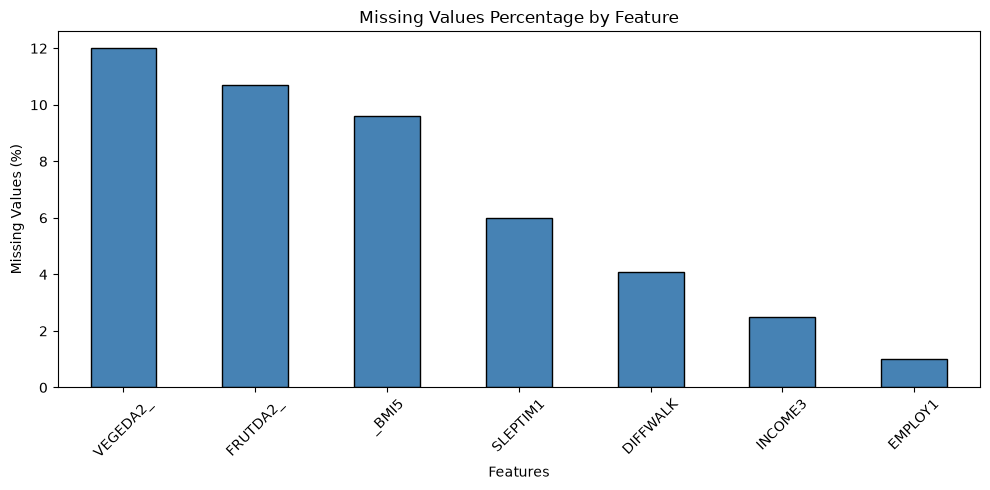

In [6]:
#Visualiser les valeurs manquantes
# Missing values visualization

plt.figure(figsize=(10, 5))

missing["Percentage (%)"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Examiner les réponses
# Analyse des codes spéciaux BRFSS

for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())
#Ce code permet d'afficher les différentes valeurs de chaque colonne ainsi que leur fréquence


--- _AGE80 ---
_AGE80
18      7
19     12
20     13
21      4
22     15
     ... 
76     20
77     19
78     28
79     15
80    101
Name: count, Length: 63, dtype: int64

--- SEXVAR ---
SEXVAR
1    466
2    534
Name: count, dtype: int64

--- EDUCA ---
EDUCA
1      1
2     19
3     36
4    266
5    262
6    413
9      3
Name: count, dtype: int64

--- INCOME3 ---
INCOME3
1.0      24
2.0      17
3.0      25
4.0      54
5.0      95
6.0     113
7.0     118
8.0     105
9.0     122
10.0     56
11.0     66
77.0     88
99.0     92
NaN      25
Name: count, dtype: int64

--- EMPLOY1 ---
EMPLOY1
1.0    410
2.0     76
3.0     15
4.0     20
5.0     36
6.0     25
7.0    332
8.0     65
9.0     11
NaN     10
Name: count, dtype: int64

--- _BMI5 ---
_BMI5
1653.0     1
1660.0     1
1711.0     1
1719.0     1
1731.0     1
          ..
5169.0     1
5521.0     1
6250.0     1
6338.0     1
NaN       96
Name: count, Length: 513, dtype: int64

--- GENHLTH ---
GENHLTH
1    131
2    312
3    366
4    156
5     34

In [ ]:
#Identifier les codes spéciaux
# Identification des codes spéciaux BRFSS
#Au lieu d'afficher toutes les valeurs, nous allons compter uniquement les codes correspondant aux réponses inconnues ou refusées.
special_codes = {
    "EDUCA": [9],
    "INCOME3": [77, 99],
    "EMPLOY1": [9],
    "GENHLTH": [7, 9],
    "PHYSHLTH": [77, 99],
    "MENTHLTH": [77, 99],
    "CVDCRHD4": [7, 9],
    "CVDSTRK3": [7, 9],
    "CHCKDNY2": [7, 9],
    "DIFFWALK": [7, 9],
    "_SMOKER3": [9],
    "EXERANY2": [7, 9],
    "DRNKANY6": [7, 9],
    "SLEPTIM1": [77, 99],
    "_HLTHPL2": [9],
    "DIABETE4": [7, 9]
}

results = []

for col, codes in special_codes.items():
    count = df[col].isin(codes).sum()

    results.append({
        "Feature": col,
        "Special Codes": str(codes),
        "Count": count,
        "Percentage (%)": count / len(df) * 100
    })

special_missing = pd.DataFrame(results)

special_missing

,Feature,Special Codes,Count,Percentage (%)
0,EDUCA,[9],3,0.3
1,INCOME3,"[77, 99]",180,18.0
2,EMPLOY1,[9],11,1.1
3,GENHLTH,"[7, 9]",1,0.1
4,PHYSHLTH,"[77, 99]",26,2.6
5,MENTHLTH,"[77, 99]",21,2.1
6,CVDCRHD4,"[7, 9]",6,0.6
7,CVDSTRK3,"[7, 9]",2,0.2
8,CHCKDNY2,"[7, 9]",4,0.4
9,DIFFWALK,"[7, 9]",5,0.5


In [ ]:
#Combiner les deux types de valeurs manquantes
# Analyse globale des valeurs manquantes

total_missing = pd.DataFrame({
    "NaN Values": df.isnull().sum()
})

total_missing["Special Codes"] = [
    df[col].isin(special_codes.get(col, [])).sum()
    for col in df.columns
]

total_missing["Total Missing"] = (
    total_missing["NaN Values"] +
    total_missing["Special Codes"]
)

total_missing["Percentage (%)"] = (
    total_missing["Total Missing"] / len(df) * 100
)

total_missing = total_missing.sort_values(
    by="Total Missing", ascending=False
)

total_missing
#Les zéros marqués d'un astérisque signifient qu'aucun code spécial n'a été recherché pour ces variables, et non qu'ils sont nécessairement absents.

,NaN Values,Special Codes,Total Missing,Percentage (%)
INCOME3,25,180,205,20.5
VEGEDA2_,120,0,120,12.0
FRUTDA2_,107,0,107,10.7
_BMI5,96,0,96,9.6
DRNKANY6,0,72,72,7.2
SLEPTIM1,60,7,67,6.7
_SMOKER3,0,60,60,6.0
DIFFWALK,41,5,46,4.6
_HLTHPL2,0,42,42,4.2
PHYSHLTH,0,26,26,2.6


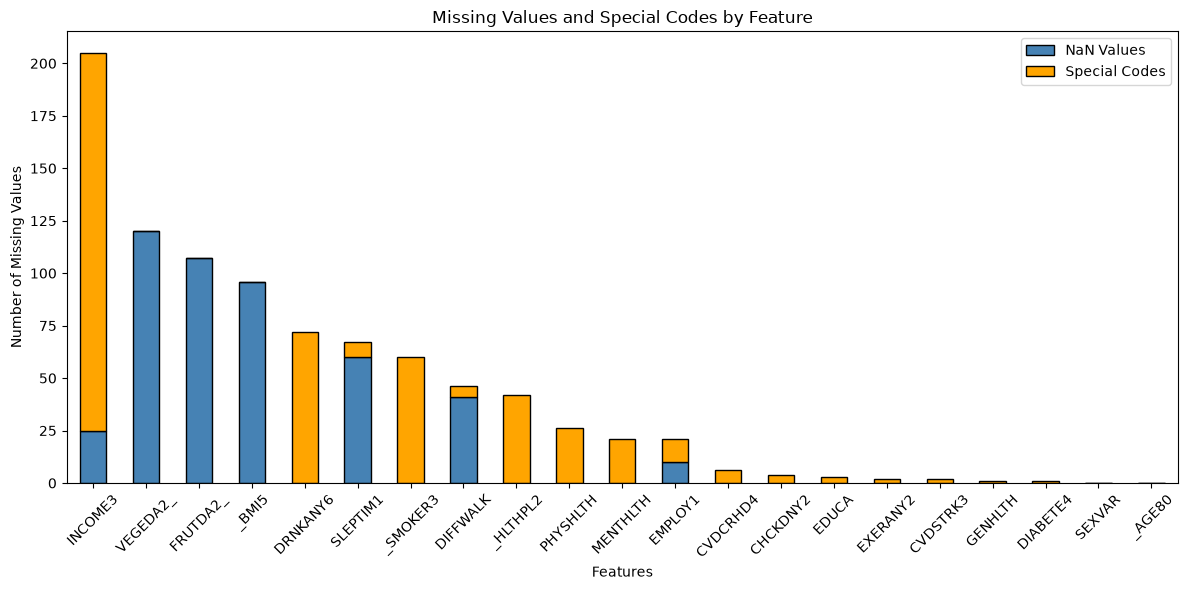

In [11]:
#Visualiser l'ensemble des valeurs manquantes/Nous allons créer un graphique qui distingue les cellules vides (NaN) des réponses codées comme manquantes.
# Visualisation globale des valeurs manquantes

total_missing[["NaN Values", "Special Codes"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Missing Values and Special Codes by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:
#Interprétation des résultats :Avant l'analyse des codes spéciaux, VEGEDA2_ était la variable présentant le plus de valeurs manquantes.
#Après cette analyse, c'est INCOME3 qui arrive en première position avec 20,5 % de réponses potentiellement manquantes.


In [13]:
#Calculer le taux global de valeurs manquantes
# Global missing values statistics

nan_count = total_missing["NaN Values"].sum()
special_count = total_missing["Special Codes"].sum()
total_count = total_missing["Total Missing"].sum()

print("NaN values:", nan_count)
print("Special codes:", special_count)
print("Total missing values:", total_count)
print("Global missing rate:", round(total_count / df.size * 100, 2), "%")

NaN values: 459
Special codes: 443
Total missing values: 902
Global missing rate: 4.3 %


### Missing Values Analysis — Conclusion

The dataset contains 1,000 observations and 21 variables.

Based on the official BRFSS 2025 codebook, we identified:

- 459 empty values (NaN).
- 443 missing values represented by special codes.
- 902 total missing values (4.30%).
- 355 observations containing at least one missing value.

INCOME3 has the highest missing rate (20.5%), followed by VEGEDA2_ (12%) and FRUTDA2_ (10.7%).

All special codes were verified using the official BRFSS 2025 codebook. However, some missing-value categories combine different reasons for non-response.

The original dataset remains unchanged. Missing-value treatment will be performed during the preprocessing stage.

Class Distribution Analysis
Maintenant, nous allons analyser la distribution des classes de la variable cible DIABETE4 (Target Y).

L'objectif est de déterminer combien de personnes sont diabétiques et non diabétiques, et de vérifier si le dataset est déséquilibré (Class Imbalance).

## 3. Class Distribution Analysis

In [14]:
# Distribution of the original target variable

target_distribution = pd.DataFrame({
    "Count": df["DIABETE4"].value_counts(dropna=False),
    "Percentage (%)": df["DIABETE4"].value_counts(
        normalize=True, dropna=False
    ) * 100
})

target_distribution.sort_index()

,Count,Percentage (%)
DIABETE4,,
1,139,13.9
2,7,0.7
3,820,82.0
4,33,3.3
7,1,0.1


Créer une target binaire pour l'analyse:
Ce code crée une variable temporaire y sans modifier le dataset original. La réponse inconnue (code 7) est exclue du calcul des fréquences.

In [15]:
# Binary target for class distribution analysis

y = df["DIABETE4"].map({
    1: 1,
    2: 0,
    3: 0,
    4: 0
})

class_distribution = pd.DataFrame({
    "Count": y.value_counts(),
    "Percentage (%)": y.value_counts(normalize=True) * 100
})

class_distribution.sort_index()

,Count,Percentage (%)
DIABETE4,,
0.0,860,86.086086
1.0,139,13.913914


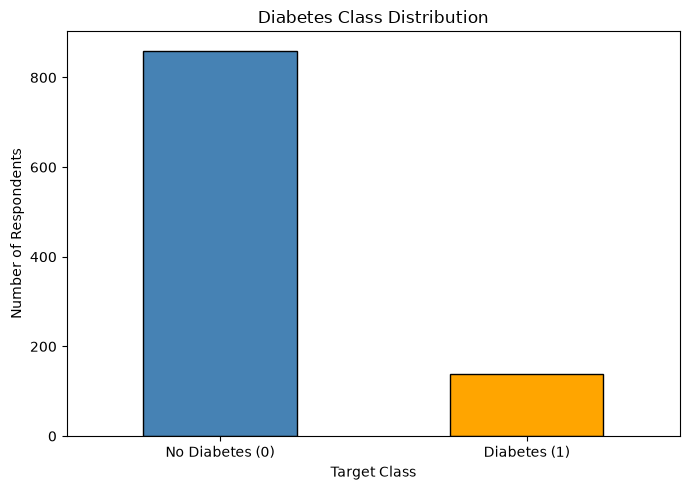

In [19]:
#Visualiser la distribution des classes
# Class distribution visualization

plt.figure(figsize=(7, 5))

y.value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Respondents")
plt.xticks([0, 1], ["No Diabetes (0)", "Diabetes (1)"], rotation=0)
plt.tight_layout()
plt.show()

### Class Distribution Analysis — Conclusion

The dataset contains 999 valid target responses:

- Class 0: 860 respondents (86.09%).
- Class 1: 139 respondents (13.91%).
- One unknown response was excluded.

The dataset is imbalanced, with a ratio of 6.19:1.
Accuracy alone is therefore not sufficient to evaluate
the classification models.

Precision, Recall, F1-score and ROC-AUC should also
be considered during model evaluation.

--Exploratory Data Analysis (EDA)
Nous allons maintenant analyser les caractéristiques des personnes diabétiques et non diabétiques.

In [20]:
# Prepare a temporary dataset for EDA

eda_df = df.copy()

# Replace missing response codes with NaN
for col, codes in special_codes.items():
    eda_df[col] = eda_df[col].replace(codes, float("nan"))

# Convert valid special codes
eda_df["PHYSHLTH"] = eda_df["PHYSHLTH"].replace(88, 0)
eda_df["MENTHLTH"] = eda_df["MENTHLTH"].replace(88, 0)

# Convert BMI to its actual scale
eda_df["_BMI5"] = eda_df["_BMI5"] / 100

# Add binary target
eda_df["Y"] = y

eda_df = eda_df.dropna(subset=["Y"])

eda_df.head()

,_AGE80,SEXVAR,EDUCA,INCOME3,EMPLOY1,_BMI5,GENHLTH,PHYSHLTH,MENTHLTH,CVDCRHD4,...,DIFFWALK,_SMOKER3,EXERANY2,DRNKANY6,SLEPTIM1,FRUTDA2_,VEGEDA2_,_HLTHPL2,DIABETE4,Y
0,80,2,4.0,NaN,7.0,18.11,5.0,5.0,0.0,2.0,...,2.0,4.0,1.0,2.0,8.0,300.0,100.0,1.0,3.0,0.0
1,53,1,6.0,9.0,1.0,27.62,2.0,1.0,4.0,2.0,...,2.0,3.0,1.0,2.0,7.0,200.0,500.0,1.0,3.0,0.0
2,60,1,5.0,4.0,1.0,NaN,4.0,0.0,0.0,2.0,...,2.0,4.0,2.0,1.0,8.0,43.0,43.0,1.0,3.0,0.0
3,80,2,6.0,6.0,7.0,27.46,2.0,0.0,0.0,2.0,...,2.0,4.0,1.0,2.0,8.0,200.0,100.0,NaN,3.0,0.0
4,40,1,4.0,8.0,2.0,31.00,1.0,0.0,15.0,2.0,...,2.0,4.0,1.0,1.0,6.0,100.0,100.0,1.0,3.0,0.0


--Analyser la distribution de l'âge
Ce graphique permettra de comparer la distribution de l'âge dans les deux classes, indépendamment de leur différence d'effectif.

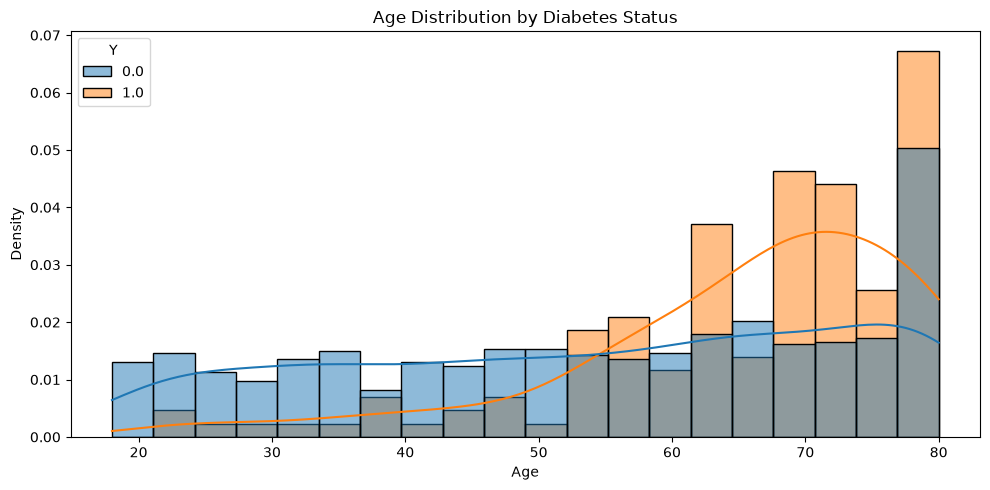

In [21]:
# Age distribution by diabetes status

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="_AGE80",
    hue="Y",
    bins=20,
    stat="density",
    common_norm=False,
    kde=True
)

plt.title("Age Distribution by Diabetes Status")
plt.xlabel("Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### Age Distribution — Interpretation

Diabetic respondents tend to be older than
non-diabetic respondents.

Age appears to be a relevant feature for
diabetes prediction.

In [25]:
#Analyser le Bmi Body Mass Index

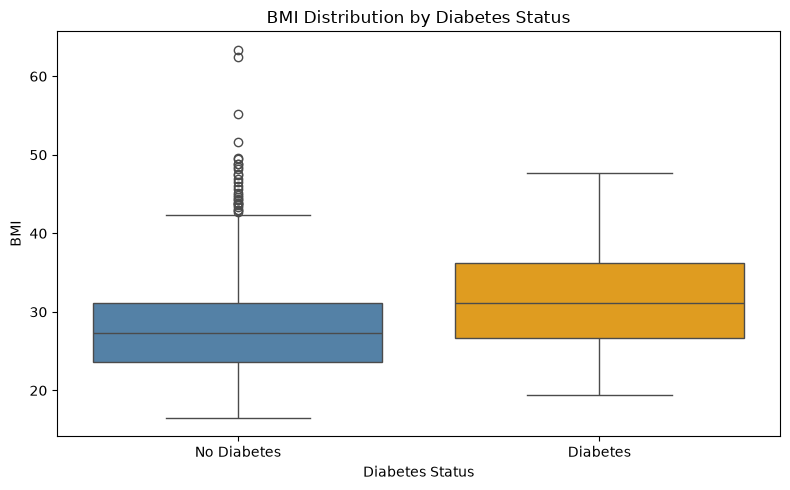

In [26]:
# BMI distribution by diabetes status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Y",
    y="_BMI5",
    hue="Y",
    palette=["steelblue", "orange"],
    legend=False
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("BMI")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.tight_layout()
plt.show()

Calculer les statistiques du BMI

In [27]:
# BMI descriptive statistics by class

eda_df.groupby("Y")["_BMI5"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
Y,,,,,,
0.0,776,28.19,27.30,6.36,16.53,63.38
1.0,127,31.67,31.17,6.25,19.37,47.67


Analyser les habitudes de vie (Lifestyle Analysis)

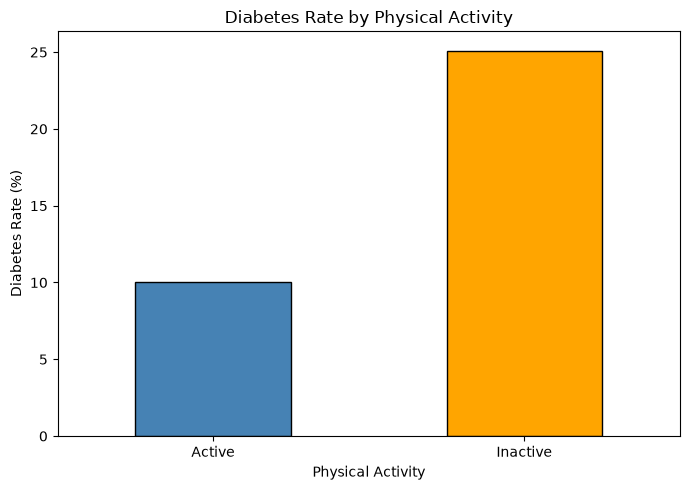

In [28]:
#Activité physique (Physical Activity):La variable EXERANY2 représente l'activité physique
# Diabetes rate by physical activity

activity = eda_df.groupby("EXERANY2")["Y"].mean() * 100

activity.index = ["Active", "Inactive"]

activity.plot(
    kind="bar",
    color=["steelblue", "orange"],
    edgecolor="black",
    figsize=(7, 5)
)

plt.title("Diabetes Rate by Physical Activity")
plt.xlabel("Physical Activity")
plt.ylabel("Diabetes Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

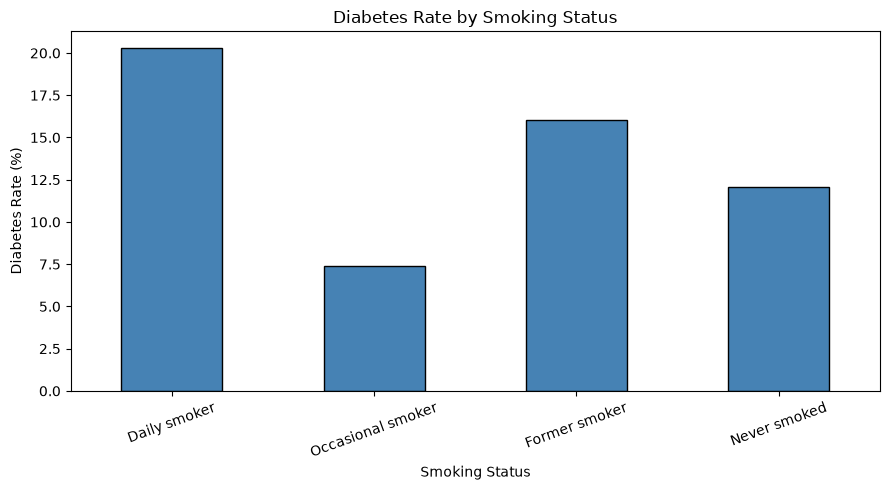

In [29]:
#Tabagisme (Smoking)
# Diabetes rate by smoking status

smoking = eda_df.groupby("_SMOKER3")["Y"].mean() * 100

smoking = smoking.rename(index={
    1: "Daily smoker",
    2: "Occasional smoker",
    3: "Former smoker",
    4: "Never smoked"
})

smoking.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black",
    figsize=(9, 5)
)

plt.title("Diabetes Rate by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Diabetes Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

 Correlation Analysis

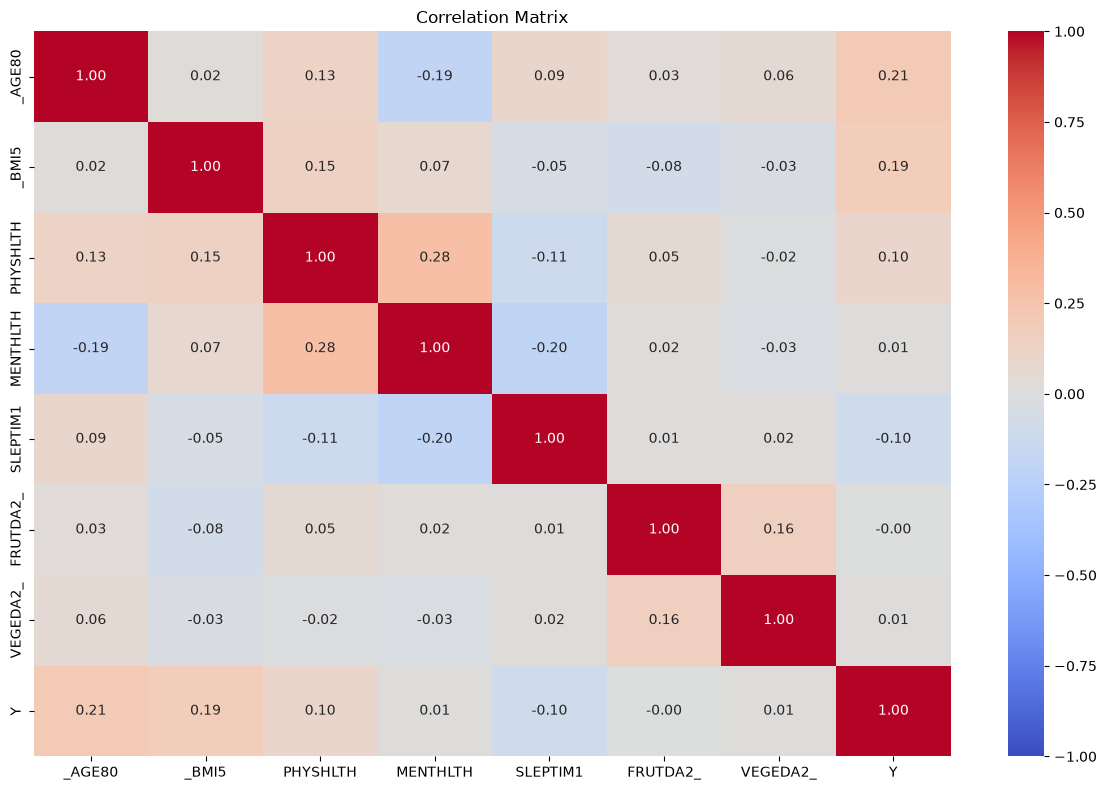

In [30]:
# Correlation matrix

numeric_features = [
    "_AGE80", "_BMI5", "PHYSHLTH",
    "MENTHLTH", "SLEPTIM1",
    "FRUTDA2_", "VEGEDA2_", "Y"
]

corr = eda_df[numeric_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [31]:
#Classer les features selon leur corrélation avec Y
# Correlation with the target variable

target_corr = corr["Y"].drop("Y")

target_corr.sort_values(
    key=abs,
    ascending=False
).round(3)

_AGE80      0.209
_BMI5       0.187
PHYSHLTH    0.101
SLEPTIM1   -0.095
VEGEDA2_    0.013
MENTHLTH    0.009
FRUTDA2_   -0.004
Name: Y, dtype: float64

In [33]:
#Feature Selection and Justification

### Feature Selection Justification

- Demographic features: Age and sex may be associated
  with diabetes status.

- Socioeconomic features: Education, income, employment
  and healthcare coverage provide social context.

- Physical and mental health features: Describe the
  respondent's general health and physical condition.

- Medical history features: Identify existing health
  conditions associated with diabetes.

- Lifestyle features: Describe physical activity,
  smoking, alcohol consumption, sleep and nutrition.

The target variable is DIABETE4, transformed into
a binary variable Y.

In [35]:
#Séparer les features X et la target Y
# Define features and target for analysis

X = eda_df.drop(columns=["DIABETE4", "Y"])
Y = eda_df["Y"]

print("Features shape:", X.shape)
print("Target shape:", Y.shape)
print("Number of features:", X.shape[1])


Features shape: (999, 20)
Target shape: (999,)
Number of features: 20
